# Systemy Operacyjne Laboratorium: 2

In [12]:
import random
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

## Konfiguracja symulacji

In [13]:
class SimulationConfig:
    def __init__(self):
        self.disk_size = 500
        self.head_start = 400
        self.num_requests = 180
        self.max_time = 35
        self.max_deadline_offset = 500
        self.request_counts = [20, 40, 60, 80, 100]
        self.dynamic_requests_count = 80
        self.random_generation = True
        self.random_seed = 35
        self.initial_direction = "up"
        self.predefined_requests = [98, 183, 37, 122, 14, 124, 65, 67]
        self.predefined_rt_requests = [(98, 120, 0), (183, 140, 5), (37, 90, 10),
                                      (122, 160, 15), (14, 70, 20), (124, 180, 25),
                                      (65, 110, 30), (67, 130, 35)]

### FCFS

In [14]:
def fcfs(requests, head):
    sequence = [head]
    total_seek_time = 0
    current_position = head

    for request in requests:
        total_seek_time += abs(request - current_position)
        current_position = request
        sequence.append(request)

    return total_seek_time, sequence

### SSTF

In [15]:
def sstf(requests, head):
    remaining_requests = requests.copy()
    sequence = [head]
    total_seek_time = 0
    current_position = head

    while remaining_requests:
        closest_request = min(remaining_requests, key=lambda x: abs(x - current_position))
        total_seek_time += abs(closest_request - current_position)
        current_position = closest_request
        sequence.append(closest_request)
        remaining_requests.remove(closest_request)

    return total_seek_time, sequence

### SCAN

In [16]:
def scan(requests, head, disk_size, direction="up"):
    requests_sorted = sorted(requests)
    sequence = [head]
    total_seek_time = 0
    current_position = head

    upper_requests = [r for r in requests_sorted if r >= head]
    lower_requests = [r for r in requests_sorted if r < head]

    if direction == "up":
        for request in upper_requests:
            total_seek_time += abs(request - current_position)
            current_position = request
            sequence.append(request)

        if lower_requests:
            total_seek_time += abs(disk_size - 1 - current_position)
            current_position = disk_size - 1
            sequence.append(disk_size - 1)

            for request in sorted(lower_requests, reverse=True):
                total_seek_time += abs(request - current_position)
                current_position = request
                sequence.append(request)
    else:
        for request in sorted(lower_requests, reverse=True):
            total_seek_time += abs(request - current_position)
            current_position = request
            sequence.append(request)

        if upper_requests:
            total_seek_time += abs(current_position - 0)
            current_position = 0
            sequence.append(0)

            for request in upper_requests:
                total_seek_time += abs(request - current_position)
                current_position = request
                sequence.append(request)

    return total_seek_time, sequence

### C-SCAN

In [17]:
def cscan(requests, head, disk_size):
    requests_sorted = sorted(requests)
    sequence = [head]
    total_seek_time = 0
    current_position = head

    upper_requests = [r for r in requests_sorted if r >= head]
    lower_requests = [r for r in requests_sorted if r < head]

    for request in upper_requests:
        total_seek_time += abs(request - current_position)
        current_position = request
        sequence.append(request)

    if lower_requests:
        total_seek_time += abs(disk_size - 1 - current_position)
        current_position = disk_size - 1
        sequence.append(disk_size - 1)

        total_seek_time += disk_size - 1
        current_position = 0
        sequence.append(0)

        for request in lower_requests:
            total_seek_time += abs(request - current_position)
            current_position = request
            sequence.append(request)

    return total_seek_time, sequence

### EDF

In [18]:
def edf(requests_with_deadlines, head, current_time=0):
    requests_sorted = sorted(requests_with_deadlines, key=lambda x: x[1])

    sequence = [head]
    total_seek_time = 0
    current_position = head
    missed_deadlines = 0

    for req_pos, deadline, arrival_time in requests_sorted:
        seek_time = abs(req_pos - current_position)
        current_time += seek_time

        if current_time > deadline:
            missed_deadlines += 1

        total_seek_time += seek_time
        current_position = req_pos
        sequence.append(req_pos)

        current_time += 1

    return total_seek_time, sequence, missed_deadlines

### FD-SCAN

In [19]:
def fd_scan(requests_with_deadlines, head, current_time=0):
    sequence = [head]
    total_seek_time = 0
    current_position = head
    missed_deadlines = 0

    requests = sorted(requests_with_deadlines, key=lambda x: x[2])
    remaining_requests = []

    while requests or remaining_requests:
        while requests and requests[0][2] <= current_time:
            remaining_requests.append(requests.pop(0))

        if not remaining_requests:
            if requests:
                current_time = requests[0][2]
                continue
            else:
                break

        feasible_requests = []

        for req_pos, deadline, arrival_time in remaining_requests:
            seek_time = abs(req_pos - current_position)
            if deadline > current_time + seek_time + 1:
                feasible_requests.append((req_pos, deadline, arrival_time))

        if not feasible_requests:
            next_request = min(remaining_requests, key=lambda x: x[1])
        else:
            next_request = min(feasible_requests, key=lambda x: x[1])

        scan_direction = "up" if next_request[0] >= current_position else "down"

        remaining_requests.remove(next_request)
        req_pos, deadline, arrival_time = next_request

        if scan_direction == "up":
            requests_in_path = [(r[0], r[1], r[2]) for r in remaining_requests if r[0] >= current_position]
            requests_in_path.sort(key=lambda x: x[0])
        else:
            requests_in_path = [(r[0], r[1], r[2]) for r in remaining_requests if r[0] <= current_position]
            requests_in_path.sort(key=lambda x: x[0], reverse=True)

        if scan_direction == "up" and req_pos >= current_position:
            requests_in_path.insert(0, (req_pos, deadline, arrival_time))
        elif scan_direction == "down" and req_pos <= current_position:
            requests_in_path.insert(0, (req_pos, deadline, arrival_time))
        else:
            requests_in_path = [(req_pos, deadline, arrival_time)] + requests_in_path

        for req_pos, deadline, arrival_time in requests_in_path:
            seek_time = abs(req_pos - current_position)
            current_time += seek_time

            if current_time > deadline:
                missed_deadlines += 1

            total_seek_time += seek_time
            current_position = req_pos
            sequence.append(req_pos)

            if (req_pos, deadline, arrival_time) in remaining_requests:
                remaining_requests.remove((req_pos, deadline, arrival_time))

            current_time += 1

            while requests and requests[0][2] <= current_time:
                remaining_requests.append(requests.pop(0))

    return total_seek_time, sequence, missed_deadlines

## Generowanie danych i wykresów

In [20]:
def generate_requests(config, real_time=False, initial_requests=None):
    if config.random_generation:
        random.seed(config.random_seed)
        requests = initial_requests or []

        num_to_generate = config.num_requests if initial_requests is None else config.dynamic_requests_count

        for _ in range(num_to_generate):
            position = random.randint(0, config.disk_size - 1)

            if real_time:
                arrival_time = random.randint(0, config.max_time)
                deadline_offset = random.randint(1, config.max_deadline_offset)
                deadline = arrival_time + deadline_offset
                requests.append((position, deadline, arrival_time))
            else:
                requests.append(position)

        if real_time:
            return sorted(requests, key=lambda x: x[2])
        else:
            return requests
    else:
        if real_time:
            return config.predefined_rt_requests
        else:
            return config.predefined_requests

def test_algorithms(config):
    real_time_requests = generate_requests(config, real_time=True)
    standard_requests = [req[0] for req in real_time_requests]

    results = []

    fcfs_seek_time, fcfs_sequence = fcfs(standard_requests, config.head_start)
    results.append({"Algorithm": "FCFS", "Total Seek Time": fcfs_seek_time, "Type": "Standard"})

    sstf_seek_time, sstf_sequence = sstf(standard_requests, config.head_start)
    results.append({"Algorithm": "SSTF", "Total Seek Time": sstf_seek_time, "Type": "Standard"})

    scan_seek_time, scan_sequence = scan(standard_requests, config.head_start, config.disk_size, config.initial_direction)
    results.append({"Algorithm": "SCAN", "Total Seek Time": scan_seek_time, "Type": "Standard"})

    cscan_seek_time, cscan_sequence = cscan(standard_requests, config.head_start, config.disk_size)
    results.append({"Algorithm": "C-SCAN", "Total Seek Time": cscan_seek_time, "Type": "Standard"})

    edf_seek_time, edf_sequence, edf_missed = edf(real_time_requests, config.head_start)
    results.append({
        "Algorithm": "EDF",
        "Total Seek Time": edf_seek_time,
        "Missed Deadlines": edf_missed,
        "Type": "Real-time"
    })

    fd_scan_seek_time, fd_scan_sequence, fd_scan_missed = fd_scan(real_time_requests, config.head_start, config.disk_size)
    results.append({
        "Algorithm": "FD-SCAN",
        "Total Seek Time": fd_scan_seek_time,
        "Missed Deadlines": fd_scan_missed,
        "Type": "Real-time"
    })

    df_results = pd.DataFrame(results[:4])
    print(df_results)

    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_results, x="Algorithm", y="Total Seek Time", hue="Type")
    plt.title("Porównanie algorytmów planowania dostępu do dysku")
    plt.ylabel("Całkowity czas ruchu głowicy")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(14, 8))

    plt.subplot(2, 3, 1)
    plt.plot(range(len(fcfs_sequence)), fcfs_sequence, marker='o')
    plt.title("FCFS")
    plt.xlabel("Kolejność obsługi")
    plt.ylabel("Pozycja na dysku")

    plt.subplot(2, 3, 2)
    plt.plot(range(len(sstf_sequence)), sstf_sequence, marker='o')
    plt.title("SSTF")
    plt.xlabel("Kolejność obsługi")
    plt.ylabel("Pozycja na dysku")

    plt.subplot(2, 3, 3)
    plt.plot(range(len(scan_sequence)), scan_sequence, marker='o')
    plt.title("SCAN")
    plt.xlabel("Kolejność obsługi")
    plt.ylabel("Pozycja na dysku")

    plt.subplot(2, 3, 4)
    plt.plot(range(len(cscan_sequence)), cscan_sequence, marker='o')
    plt.title("C-SCAN")
    plt.xlabel("Kolejność obsługi")
    plt.ylabel("Pozycja na dysku")

    plt.subplot(2, 3, 5)
    plt.plot(range(len(edf_sequence)), edf_sequence, marker='o')
    plt.title(f"EDF")
    plt.xlabel("Kolejność obsługi")
    plt.ylabel("Pozycja na dysku")

    plt.subplot(2, 3, 6)
    plt.plot(range(len(fd_scan_sequence)), fd_scan_sequence, marker='o')
    plt.title(f"FD-SCAN")
    plt.xlabel("Kolejność obsługi")
    plt.ylabel("Pozycja na dysku")

    plt.tight_layout()
    plt.show()

    return df_results

def test_with_different_workloads(config):
    all_results = []

    for num_requests in config.request_counts:
        temp_config = SimulationConfig()
        temp_config.num_requests = num_requests
        temp_config.random_generation = config.random_generation
        temp_config.random_seed = config.random_seed

        real_time_requests = generate_requests(temp_config, real_time=True)

        edf_seek_time, _, edf_missed = edf(real_time_requests, config.head_start)
        fd_scan_seek_time, _, fd_scan_missed = fd_scan(real_time_requests, config.head_start, config.disk_size)

        all_results.extend([
            {"Algorithm": "EDF", "Requests": num_requests, "Total Seek Time": edf_seek_time, "Missed Deadlines": edf_missed},
            {"Algorithm": "FD-SCAN", "Requests": num_requests, "Total Seek Time": fd_scan_seek_time, "Missed Deadlines": fd_scan_missed}
        ])

    df_workload = pd.DataFrame(all_results)

    plt.figure(figsize=(12, 10))

    plt.subplot(2, 1, 1)
    sns.lineplot(data=df_workload, x="Requests", y="Total Seek Time", hue="Algorithm", marker="o")
    plt.title("Wpływ liczby żądań na całkowity czas ruchu głowicy")
    plt.xlabel("Liczba żądań")
    plt.ylabel("Całkowity czas ruchu głowicy")

    plt.subplot(2, 1, 2)
    sns.lineplot(data=df_workload, x="Requests", y="Missed Deadlines", hue="Algorithm", marker="o")
    plt.title("Wpływ liczby żądań na liczbę przekroczonych terminów")
    plt.xlabel("Liczba żądań")
    plt.ylabel("Liczba przekroczonych terminów")

    plt.tight_layout()
    plt.show()

    return df_workload

def test_with_dynamic_request_generation(config):
    initial_requests = generate_requests(config, real_time=True)

    dynamic_config = SimulationConfig()
    dynamic_config.random_generation = config.random_generation
    dynamic_config.random_seed = config.random_seed + 1
    dynamic_config.max_time = config.max_time * 2

    dynamic_requests = []
    if config.random_generation:
        dynamic_requests = generate_requests(dynamic_config, real_time=True)

        for i in range(len(dynamic_requests)):
            pos, deadline, arrival = dynamic_requests[i]
            arrival = arrival + config.max_time // 3
            deadline = arrival + random.randint(1, config.max_deadline_offset)
            dynamic_requests[i] = (pos, deadline, arrival)
    else:
        dynamic_requests = [(150, 200, 50), (80, 180, 60), (30, 100, 70),
                           (120, 200, 80), (55, 140, 90)]

    all_requests = initial_requests + dynamic_requests
    all_requests.sort(key=lambda x: x[2])

    fd_scan_seek_time, fd_scan_sequence, fd_scan_missed = fd_scan(all_requests, config.head_start, config.disk_size)
    edf_seek_time, edf_sequence, edf_missed = edf(all_requests, config.head_start)

    times = []
    positions = []
    deadlines = []
    algorithms = []

    current_time = 0
    head_pos = config.head_start

    EDF_MISSED = 0

    for i, pos in enumerate(edf_sequence):
        if i > 0:
            seek_time = abs(pos - head_pos)
            current_time += seek_time + 1

            for j, (req_pos, req_deadline, req_arrival) in enumerate(all_requests):
                if req_pos == pos:
                    times.append(current_time)
                    positions.append(pos)
                    deadlines.append(req_deadline)
                    algorithms.append("EDF")
                    EDF_MISSED = [time > deadline for time, deadline in zip(times, deadlines)]
                    break

            head_pos = pos

    current_time = 0
    head_pos = config.head_start

    FD_SCAN_MISSED = 0

    for i, pos in enumerate(fd_scan_sequence):
        if i > 0:
            seek_time = abs(pos - head_pos)
            current_time += seek_time + 1

            for j, (req_pos, req_deadline, req_arrival) in enumerate(all_requests):
                if req_pos == pos:
                    times.append(current_time)
                    positions.append(pos)
                    deadlines.append(req_deadline)
                    algorithms.append("FD-SCAN")
                    FD_SCAN_MISSED = [time > deadline for time, deadline in zip(times, deadlines)]
                    break

            head_pos = pos

    df_dynamic = pd.DataFrame({
        "Time": times,
        "Position": positions,
        "Deadline": deadlines,
        "Algorithm": algorithms,
        "Missed": [time > deadline for time, deadline in zip(times, deadlines)]
    })

    plt.figure(figsize=(14, 10))

    plt.subplot(2, 1, 1)
    sns.scatterplot(data=df_dynamic[df_dynamic["Algorithm"] == "EDF"],
                   x="Time", y="Position", hue="Missed", style="Missed",
                   palette={True: "red", False: "green"})
    plt.title(f"EDF - Obsługa żądań w czasie")
    plt.xlabel("Czas symulacji")
    plt.ylabel("Pozycja na dysku")

    plt.subplot(2, 1, 2)
    sns.scatterplot(data=df_dynamic[df_dynamic["Algorithm"] == "FD-SCAN"],
                   x="Time", y="Position", hue="Missed", style="Missed",
                   palette={True: "red", False: "green"})
    plt.title(f"FD-SCAN - Obsługa żądań w czasie")
    plt.xlabel("Czas symulacji")
    plt.ylabel("Pozycja na dysku")

    plt.tight_layout()
    plt.show()

    results = [
        {"Algorithm": "EDF", "Total Seek Time": edf_seek_time, "Missed Deadlines": EDF_MISSED.count(True)},
        {"Algorithm": "FD-SCAN", "Total Seek Time": fd_scan_seek_time, "Missed Deadlines": FD_SCAN_MISSED.count(True)}
    ]

    print(pd.DataFrame(results))

    return df_dynamic

## Głodzenie symulacji

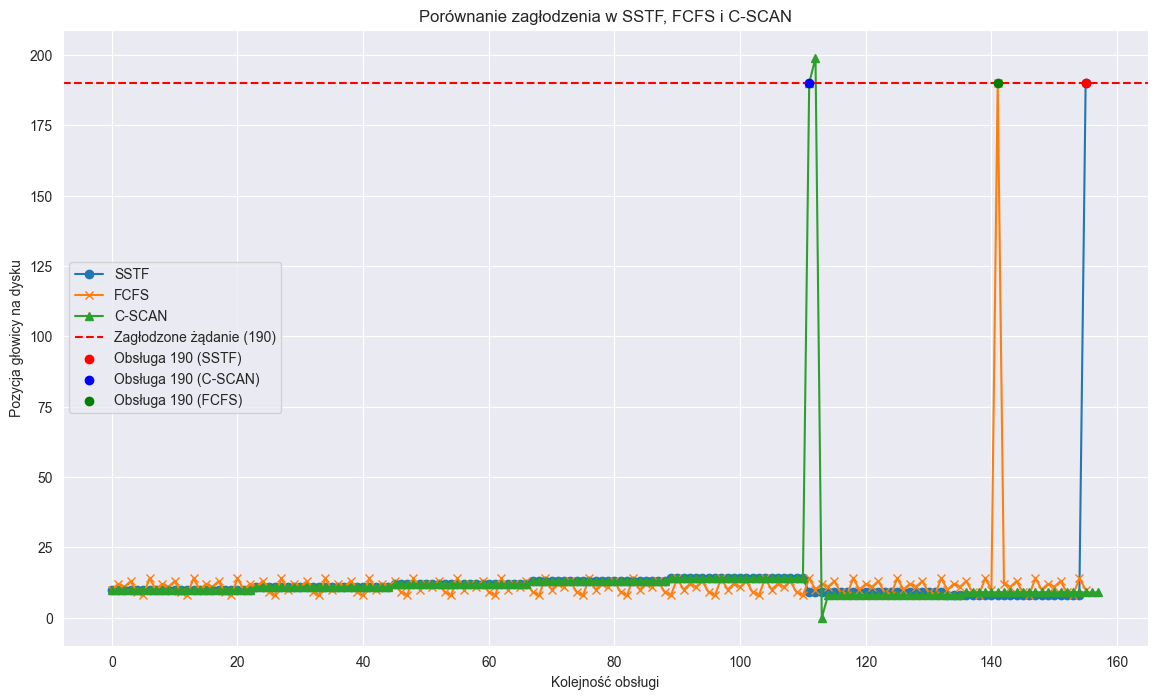

SSTF: żądanie 190 obsłużone po 155 operacjach
FCFS: żądanie 190 obsłużone po 141 operacjach
C-SCAN: żądanie 190 obsłużone po 111 operacjach


In [21]:
def fcfs_starv(requests, head):
    sequence = [head]
    positions = [head]
    pending = requests.copy()
    for req in pending:
        head = req
        sequence.append(head)
        positions.append(head)
    return sequence, positions

def sstf_starv(requests, head):
    sequence = [head]
    positions = [head]
    pending = requests.copy()
    while pending:
        closest = min(pending, key=lambda x: abs(x - head))
        head = closest
        sequence.append(head)
        positions.append(head)
        pending.remove(closest)
    return sequence, positions

def cscan_starv(requests, head, disk_size):
    sequence = [head]
    positions = [head]
    pending = sorted(requests)
    current = head
    upper = [r for r in pending if r >= current]
    lower = [r for r in pending if r < current]
    for req in upper:
        current = req
        sequence.append(current)
        positions.append(current)
    if lower:
        current = disk_size - 1
        sequence.append(current)
        positions.append(current)
        current = 0
        sequence.append(current)
        positions.append(current)
        for req in lower:
            current = req
            sequence.append(current)
            positions.append(current)
    return sequence, positions

def starvation_comparison_plot():
    disk_size = 200
    head = 10
    starving_request = 190
    frequent_requests = [12, 11, 13, 9, 8, 14, 10, 12, 11, 13, 9, 8, 14, 10] * 10
    requests = frequent_requests + [starving_request] + [12, 11, 13, 9, 8, 14, 10, 12, 11, 13, 9, 8, 14, 10]

    sstf_seq, sstf_pos = sstf_starv(requests, head)
    fcfs_seq, fcfs_pos = fcfs_starv(requests, head)
    cscan_seq, cscan_pos = cscan_starv(requests, head, disk_size)

    def find_step(seq, target):
        for i, v in enumerate(seq):
            if v == target:
                return i
        return None

    sstf_starve = find_step(sstf_seq, starving_request)
    fcfs_starve = find_step(fcfs_seq, starving_request)
    cscan_starve = find_step(cscan_seq, starving_request)

    plt.figure(figsize=(14, 8))
    plt.plot(range(len(sstf_pos)), sstf_pos, marker='o', label='SSTF')
    plt.plot(range(len(fcfs_pos)), fcfs_pos, marker='x', label='FCFS')
    plt.plot(range(len(cscan_pos)), cscan_pos, marker='^', label='C-SCAN')
    plt.axhline(y=starving_request, color='red', linestyle='--', label='Zagłodzone żądanie (190)')

    if sstf_starve is not None:
        plt.scatter(sstf_starve, starving_request, color='red', zorder=5, label='Obsługa 190 (SSTF)')
    if cscan_starve is not None:
        plt.scatter(cscan_starve, starving_request, color='blue', zorder=5, label='Obsługa 190 (C-SCAN)')
    if fcfs_starve is not None:
        plt.scatter(fcfs_starve, starving_request, color='green', zorder=5, label='Obsługa 190 (FCFS)')

    plt.title('Porównanie zagłodzenia w SSTF, FCFS i C-SCAN')
    plt.xlabel('Kolejność obsługi')
    plt.ylabel('Pozycja głowicy na dysku')
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"SSTF: żądanie 190 obsłużone po {sstf_starve} operacjach")
    print(f"FCFS: żądanie 190 obsłużone po {fcfs_starve} operacjach")
    print(f"C-SCAN: żądanie 190 obsłużone po {cscan_starve} operacjach")

starvation_comparison_plot()

## Uruchomienie symulacji

  Algorithm  Total Seek Time      Type
0      FCFS            31687  Standard
1      SSTF              895  Standard
2      SCAN              594  Standard
3    C-SCAN              996  Standard


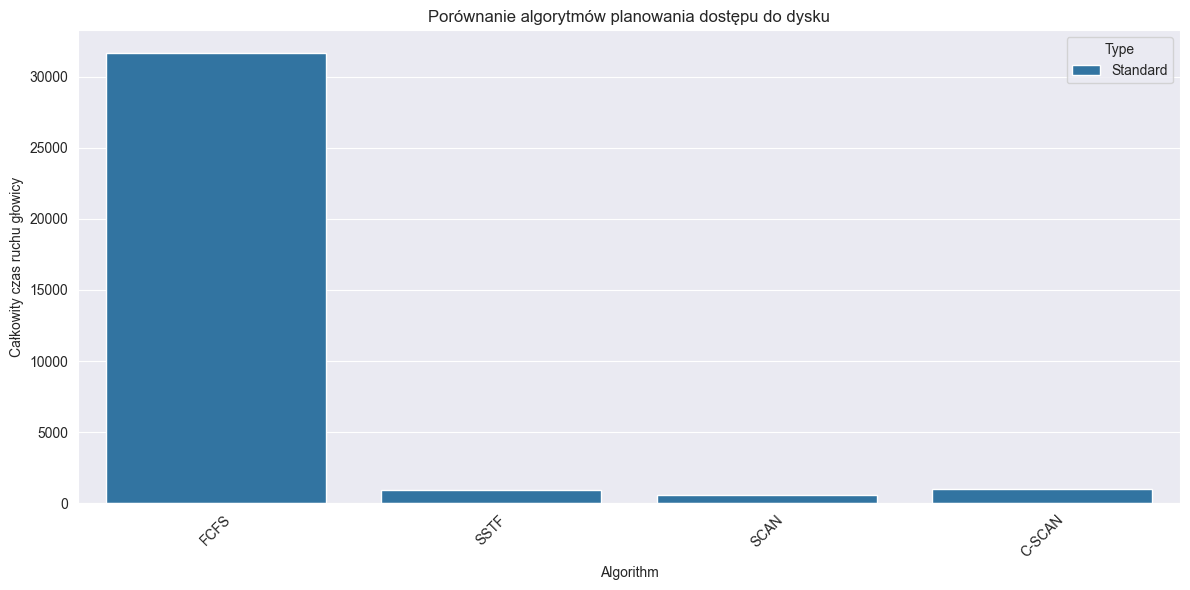

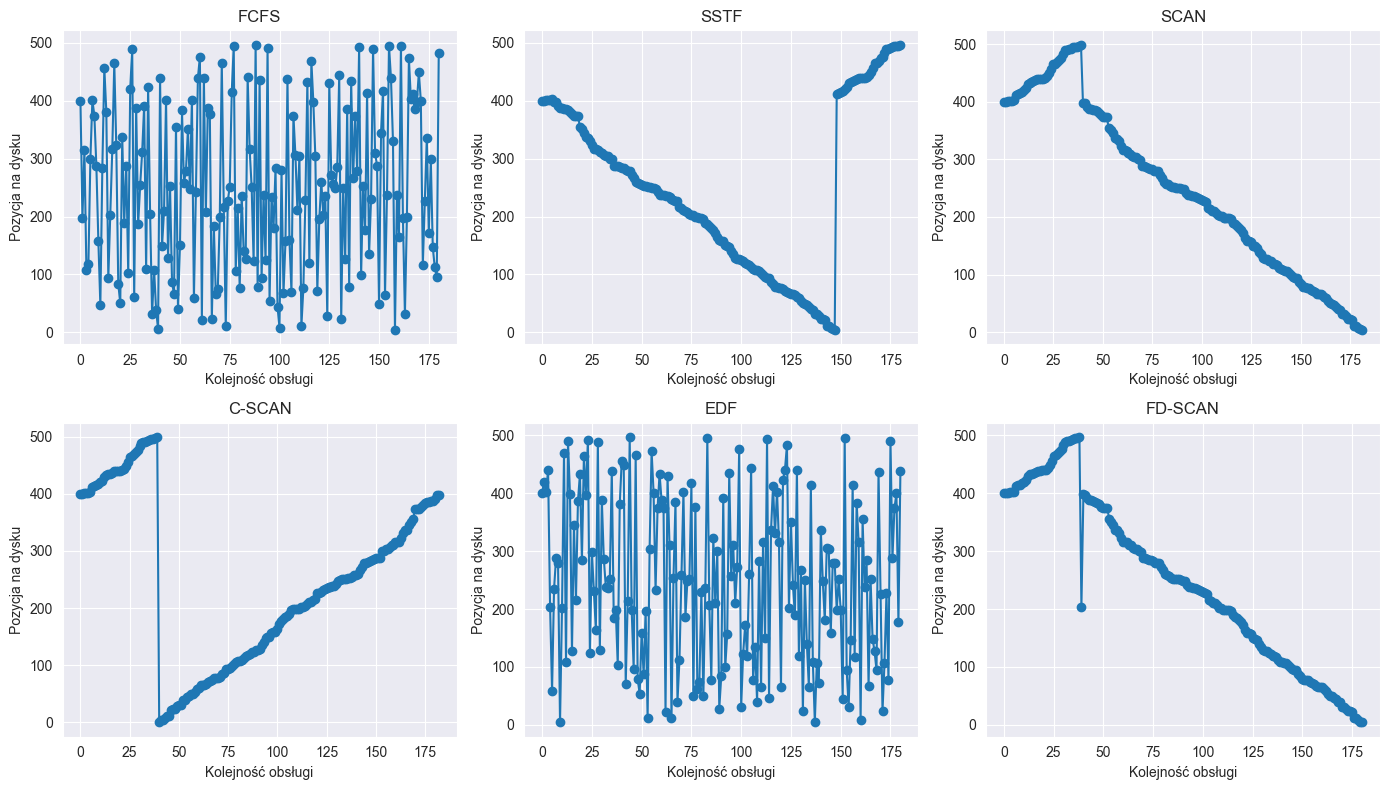

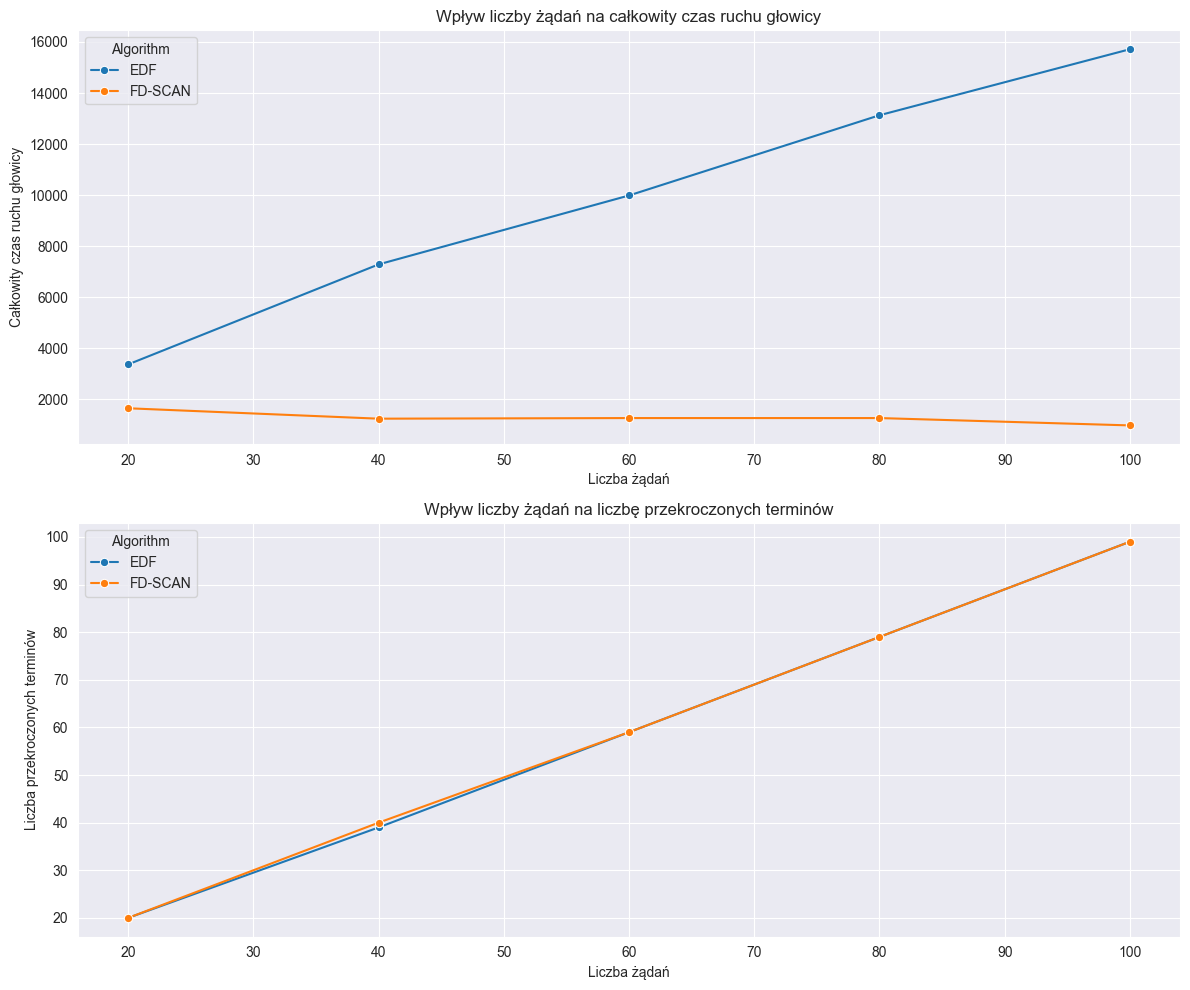

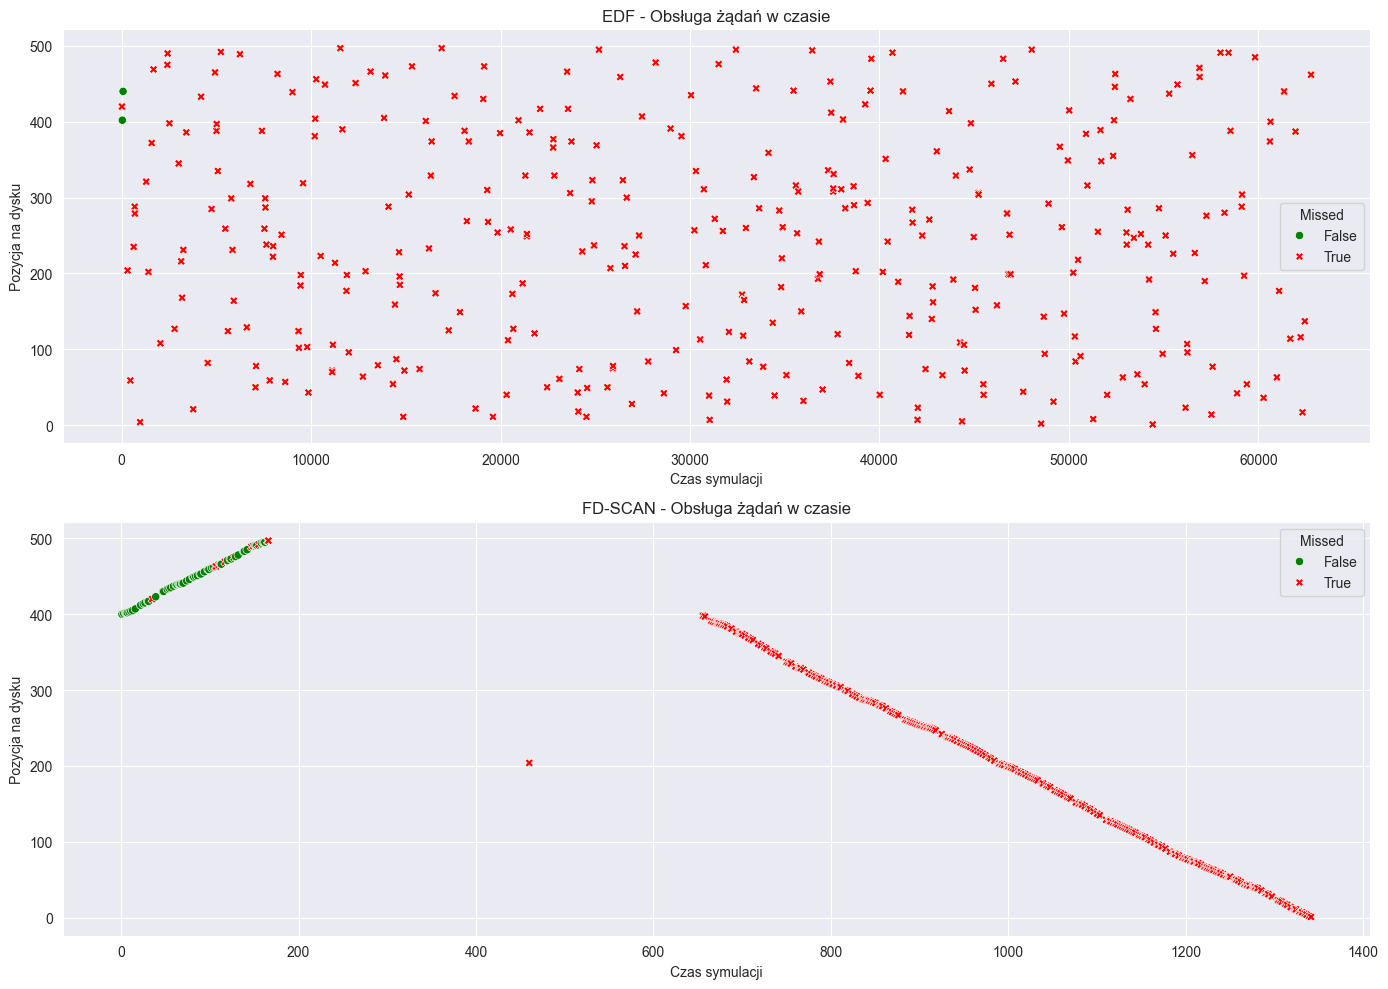

  Algorithm  Total Seek Time  Missed Deadlines
0       EDF            62418               358
1   FD-SCAN              981               660


In [22]:
def main():
    config = SimulationConfig()

    results1 = test_algorithms(config)

    results2 = test_with_different_workloads(config)

    results3 = test_with_dynamic_request_generation(config)

if __name__ == "__main__":
    main()